<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS15 - Pipeline Machine Learning & Deployment — RumahPoint
### Siklus Penuh MLOps: Preprocessing Anti-Leakage, Deep Neural Network Keras 3, Serialisasi Artefak Produksi, dan Deployment Container Docker ke Hugging Face Spaces
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi  
**Politeknik Negeri Malang**


---

## Justifikasi Adaptasi Kurikulum Modul ke Domain PBL RumahPoint

Pada Jobsheet 15 modul standar, materi praktikum mendemonstrasikan klasifikasi citra sederhana (*Day vs Night*) menggunakan ekstraksi fitur HOG, normalisasi scaler, neural network biner, dan deployment Flask via Docker ke Hugging Face Spaces. Seluruh siklus praktikum dan tugas mandiri pada jobsheet ini diadaptasikan secara penuh dan terintegrasi langsung ke dataset proyek PBL (**RumahPoint — `properti_multi_kota_clean.csv`**) dengan landasan teknis sebagai berikut:

### 1. Keselarasan Domain Proyek PBL & Ketiadaan Dataset Citra
- Folder `Dataset/` pada repositori proyek PBL secara resmi difokuskan pada data tabular real estate Indonesia (`properti_multi_kota_clean.csv`, 56.170 baris) dan tidak menyertakan berkas citra *Day vs Night*.
- Mengadaptasikan seluruh alur Praktikum 1, Praktikum 2, dan Tugas Mandiri ke dataset RumahPoint menyatukan seluruh kompetensi pembelajaran semester 5 ke dalam artefak riil yang langsung bernilai pakai untuk proyek PBL.
- Seluruh pilar kurikulum MLOps pada modul (ekstraksi & transformasi fitur, normalisasi, pemodelan Deep Neural Network, evaluasi performa, serialisasi artefak `.joblib` & model neural network, pembuatan web service Flask, pembuatan Dockerfile port 7860, hingga deployment Hugging Face Spaces) dipenuhi 100% tanpa kompromi metodologis.

### 2. Arsitektur Produksi Anti-Training-Serving Skew
Dalam sistem *production machine learning*, model neural network tidak pernah menerima data mentah secara langsung. Jika transformasi data dilakukan secara terpisah atau ad-hoc di level kode web server, sistem rentan mengalami **training-serving skew** (perbedaan representasi data antara waktu pelatihan dan waktu inferensi).

Untuk meniadakan risiko tersebut, arsitektur deployment RumahPoint menerapkan pemisahan modular 3 artefak utama:
1. **`preprocessor.joblib` (`ColumnTransformer` Scikit-Learn):** Memaketkan imputasi nilai hilang (`SimpleImputer`), penskalaan standar z-score (`StandardScaler`), dan *One-Hot Encoding* kategori (`OneHotEncoder(handle_unknown='ignore')`). Seluruh parameter statistik dipelajari eksklusif dari data latih ($X_{train}$).
2. **`model_rumahpoint.keras` (Keras 3 Native Deep Neural Network):** Model klasifikasi multikelas 3 tingkat harga (*Murah*, *Sedang*, *Mahal*) yang menerima tensor input terstandarisasi.
3. **`metadata.json`:** Metadata operasional yang menyimpan daftar Top-15 nama lokasi (`lokasi_bersih`), pemetaan label target, ambang batas harga kuantil empiris ($q_1$ Rp 483,82 jt & $q_2$ Rp 1,235 M), serta catatan *dependency pinning* versi pustaka saat pelatihan.

Dengan arsitektur ini, input mentah dari formulir web pengguna (teks nama kota bebas, angka luas, jumlah kamar) diproses secara identik, deterministik, dan bebas kebocoran data (*data leakage*).


---

# Bagian 1 — Data Loading & Pipeline Preprocessing Anti-Leakage

Pada tahap ini, kita menyiapkan lingkungan komputasi, mencatat versi dependensi utama (*dependency pinning*), memuat dataset `properti_multi_kota_clean.csv` melalui **Dual-Mode Loader**, melakukan partisi data 3 arah (*Train / Validation / Test*), serta menyusun Scikit-Learn `ColumnTransformer` anti-kebocoran data.


In [1]:
# ==============================================================================
# 1. IMPORT PUSTAKA UTAMA & PENCATATAN DEPENDENCY PINNING (MLOps)
# ==============================================================================
import os
import sys
import json
import shutil
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Metrics
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# Deep Learning Framework: TensorFlow & Keras 3
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

# Web Framework untuk Simulasi Deployment
import flask
from flask import Flask, request, jsonify, render_template_string

# Cetak versi pustaka utama untuk audit reproduktibilitas container Docker
print("=" * 65)
print("CATATAN DEPENDENCY PINNING SISTEM MLOps RUMAHPOINT:")
print(f"  - Python         : {sys.version.split()[0]}")
print(f"  - NumPy          : {np.__version__}")
print(f"  - Pandas         : {pd.__version__}")
print(f"  - Scikit-Learn   : {sklearn.__version__}")
print(f"  - TensorFlow     : {tf.__version__}")
print(f"  - Keras          : {keras.__version__}")
print(f"  - Joblib         : {joblib.__version__}")
print(f"  - Flask          : {flask.__version__}")
print("=" * 65)


CATATAN DEPENDENCY PINNING SISTEM MLOps RUMAHPOINT:
  - Python         : 3.13.18
  - NumPy          : 2.4.6
  - Pandas         : 2.2.3
  - Scikit-Learn   : 1.6.1
  - TensorFlow     : 2.21.0
  - Keras          : 3.13.2
  - Joblib         : 1.6.0
  - Flask          : 3.1.3


/tmp/ipykernel_440/261123717.py:43: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print(f"  - Flask          : {flask.__version__}")


### Pemuatan Dataset Bersih PBL via Dual-Mode Loader

data dimuat menggunakan mekanisme *Dual-Mode Loader*. Skrip mendeteksi ketersediaan berkas di direktori lokal (`../Dataset/properti_multi_kota_clean.csv`) saat dijalankan di komputer lokal/IDE, dan secara otomatis melakukan *fallback* mengunduh dari tautan resmi raw GitHub saat dieksekusi di runtime Google Colab.


In [2]:
# ==============================================================================
# 2. PEMUATAN DATASET PBL MENGGUNAKAN DUAL-MODE LOADER (DECISION_LOG.md)
# ==============================================================================
DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari penyimpanan lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Dataset berhasil dimuat: {df.shape[0]:,} baris, {df.shape[1]} kolom.")
df.head()


[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Dataset berhasil dimuat: 56,170 baris, 12 kolom.


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,kondisi,lokasi_bersih,kelas_harga,kelas_harga_biner
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08,Bekas,Tangerang,Murah,Murah
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09,Bekas,Bekasi,Sedang,Mahal
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09,Bekas,Bekasi,Mahal,Mahal
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09,Bekas,Bekasi,Mahal,Mahal
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08,Bekas,Depok,Sedang,Murah


### Definisi Target & Pencegahan Target Leakage

Target klasifikasi pada sistem produksi RumahPoint adalah **`kelas_harga`**, yang membagi properti menjadi 3 kategori seimbang berdasarkan kuantil empiris populasi ($q_1$ dan $q_2$):
1. **`Murah` (Indeks 0):** Harga $< Rp 483.819.314$ (33,33% data).
2. **`Sedang` (Indeks 1):** $Rp 483.819.314 \le 	ext{Harga} \le Rp 1.235.000.000$ (33,34% data).
3. **`Mahal` (Indeks 2):** Harga $> Rp 1.235.000.000$ (33,33% data).

**Aturan Ketat Anti Target-Leakage & Drop Kolom:**
- Kolom `harga` dan `kelas_harga_biner` wajib dihapus karena merupakan representasi langsung dari target (kebocoran fatal jika dibiarkan).
- Kolom `sumber` (portal asal scraper) dan `lokasi` (string alamat mentah non-standar) dihapus karena tidak relevan secara spasial prediktif.
- Kolom `usia_bangunan` dihapus karena memiliki *missing rate* sebesar 92,29%, sementara intisari informasinya telah diekstraksi ke kolom turunan `kondisi` (`Baru`, `Bekas`, `Tidak diketahui`).


In [3]:
# ==============================================================================
# 3. PEMISAHAN FITUR PREDIKTIF & PEMETAAN TARGET (ANTI TARGET-LEAKAGE)
# ==============================================================================
target_mapping = {'Murah': 0, 'Sedang': 1, 'Mahal': 2}
label_classes = ['Murah', 'Sedang', 'Mahal']

# Konversi target string ke integer index untuk Sparse Categorical Crossentropy
y = df['kelas_harga'].map(target_mapping).values

# Drop kolom target leakage dan non-prediktif
drop_cols = ['harga', 'kelas_harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan']
X = df.drop(columns=drop_cols)

print(f"[INFO] Fitur prediktif yang dipertahankan ({X.shape[1]} kolom): {list(X.columns)}")
print(f"[INFO] Distribusi target per kelas:")
for label, idx in target_mapping.items():
    count = np.sum(y == idx)
    pct = (count / len(y)) * 100
    print(f"  - Kelas {idx} ({label:<6}): {count:,} sampel ({pct:.2f}%)")


[INFO] Fitur prediktif yang dipertahankan (6 kolom): ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'kondisi', 'lokasi_bersih']
[INFO] Distribusi target per kelas:
  - Kelas 0 (Murah ): 18,723 sampel (33.33%)
  - Kelas 1 (Sedang): 18,727 sampel (33.34%)
  - Kelas 2 (Mahal ): 18,720 sampel (33.33%)


### Partisi Data Terstratifikasi 3 Arah (Train 70% / Val 15% / Test 15%)

Dalam standar MLOps yang kredibel, partisi data dilakukan **SEBELUM** adanya transformasi data apapun (*Anti-Leakage Split*). Data dibagi menjadi tiga subset terpisah secara terstratifikasi (`stratify=y`):
1. **Training Set (70% — 39.319 baris):** Digunakan eksklusif untuk pembelajaran parameter model neural network dan *fitting* statistik `ColumnTransformer` (median imputasi, mean/std scaler, Top-15 kategori).
2. **Validation Set (15% — 8.425 baris):** Digunakan sebagai pemantau performa selama proses iterasi pelatihan (*early stopping checkpoint* dan monitoring *loss/accuracy*).
3. **Test Set (15% — 8.426 baris):** Dibiarkan **100% steril** dari segala proses pelatihan dan pemilihan arsitektur, berfungsi sebagai tolok ukur akhir kemampuan generalisasi model saat deployment.


In [4]:
# ==============================================================================
# 4. PARTISI TERSTRATIFIKASI 3-WAY (TRAIN 70% / VAL 15% / TEST 15%)
# ==============================================================================
# Langkah 1: Pisahkan 70% Train dan 30% Temporary (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Langkah 2: Bagi 30% Temporary menjadi 15% Validation dan 15% Test (rasio 50:50 dari Temp)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"[SPLIT] Jumlah data pada masing-masing partisi:")
print(f"  - Training Set   : {X_train.shape[0]:,} sampel ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"  - Validation Set : {X_val.shape[0]:,} sampel ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"  - Test Set       : {X_test.shape[0]:,} sampel ({X_test.shape[0]/len(df)*100:.1f}%)")


[SPLIT] Jumlah data pada masing-masing partisi:
  - Training Set   : 39,319 sampel (70.0%)
  - Validation Set : 8,425 sampel (15.0%)
  - Test Set       : 8,426 sampel (15.0%)


### Reduksi Kardinalitas: Ekstraksi Top-15 Lokasi Eksklusif dari $X_{train}$

Kolom `lokasi_bersih` memiliki 588 variasi nama kota/kabupaten unik. Melakukan *One-Hot Encoding* secara mentah akan menghasilkan matriks *sparse* berdimensi 590+ kolom (*curse of dimensionality*), yang memicu *overfitting* dan memperlambat latensi inferensi saat deployment.



In [5]:
# ==============================================================================
# 5. PEMBELAJARAN TOP-15 LOKASI DARI X_train & PEMETAAN KATEGORI 'Lainnya'
# ==============================================================================
# Ambil Top-15 lokasi dengan frekuensi tertinggi HANYA dari X_train
top15_locations = X_train['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

print(f"[INFO] 15 Lokasi Utama Teratas yang Dipelajari dari X_train:")
for rank, loc_name in enumerate(top15_locations, start=1):
    freq = (X_train['lokasi_bersih'] == loc_name).sum()
    print(f"  {rank:2d}. {loc_name:<25} ({freq:,} transaksi)")

def map_top15_location(series_data, top_list):
    top_set = set(top_list)
    return series_data.apply(lambda x: str(x).strip() if str(x).strip() in top_set else 'Lainnya')

# Terapkan pemetaan pada salinan dataframe tanpa merusak data mentah
X_train_mapped = X_train.copy()
X_val_mapped = X_val.copy()
X_test_mapped = X_test.copy()

X_train_mapped['lokasi_bersih'] = map_top15_location(X_train['lokasi_bersih'], top15_locations)
X_val_mapped['lokasi_bersih'] = map_top15_location(X_val['lokasi_bersih'], top15_locations)
X_test_mapped['lokasi_bersih'] = map_top15_location(X_test['lokasi_bersih'], top15_locations)

print(f"\n[INFO] Kardinalitas lokasi setelah pemetaan: {X_train_mapped['lokasi_bersih'].nunique()} kategori (Top-15 + 'Lainnya')")


[INFO] 15 Lokasi Utama Teratas yang Dipelajari dari X_train:
   1. Bekasi                    (1,330 transaksi)
   2. Kabupaten Bogor           (1,319 transaksi)
   3. Kabupaten Bekasi          (1,254 transaksi)
   4. Kabupaten Tangerang       (1,209 transaksi)
   5. Kabupaten Bandung         (1,172 transaksi)
   6. Surabaya                  (1,152 transaksi)
   7. Kabupaten Sidoarjo        (1,146 transaksi)
   8. Tangerang Selatan         (1,064 transaksi)
   9. Depok                     (1,038 transaksi)
  10. Semarang                  (915 transaksi)
  11. Tangerang                 (875 transaksi)
  12. Bogor                     (815 transaksi)
  13. Serang                    (809 transaksi)
  14. Kabupaten Gresik          (751 transaksi)
  15. Makassar                  (668 transaksi)

[INFO] Kardinalitas lokasi setelah pemetaan: 16 kategori (Top-15 + 'Lainnya')


### Pembangunan Pipeline Preprocessing Scikit-Learn Anti-Leakage

Untuk menjamin inferensi produksi berjalan identik dengan pelatihan (*reproducible & production-ready*), kita membangun Scikit-Learn `ColumnTransformer`:
- **Fitur Numerik (`luas_m2`, `luas_bangunan`, `jumlah_kamar`, `jumlah_kamar_mandi`):**
  - `SimpleImputer(strategy='median')`: Mengisi nilai kosong (*missing value*) menggunakan nilai median dari `X_train`.
  - `StandardScaler()`: Menstandarisasi nilai fitur agar memiliki mean 0 dan variansi unit 1 ($z = rac{x - \mu}{\sigma}$).
- **Fitur Kategorikal (`lokasi_bersih`, `kondisi`):**
  - `SimpleImputer(strategy='most_frequent')`: Mengisi missing value dengan modus kategori.
  - `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: Mengonversi kategori ke biner. Pengaturan `handle_unknown='ignore'` memastikan bahwa jika ada kategori tak dikenal di masa depan, encoder tidak akan menghasilkan eror melainkan mengisi nol secara aman.

`ColumnTransformer` di-fit **HANYA** pada `X_train_mapped`, kemudian digunakan untuk mentransformasikan `X_train_mapped`, `X_val_mapped`, dan `X_test_mapped`.


In [6]:
# ==============================================================================
# 6. DEFINISI & FITTING COLUMNTRANSFORMER (ANTI-LEAKAGE PIPELINE)
# ==============================================================================
numeric_features = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']
categorical_features = ['lokasi_bersih', 'kondisi']

# Pipeline Numerik: Imputasi Median dilanjutkan Standarisasi
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline Kategorikal: Imputasi Modus dilanjutkan One-Hot Encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Integrasi ke dalam Scikit-Learn ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_features),
    ('cat', cat_pipeline, categorical_features)
])

# Fit HANYA pada data latih (X_train_mapped)
print("[PREPROCESSOR] Melakukan fitting ColumnTransformer pada X_train...")
preprocessor.fit(X_train_mapped)

# Transformasikan subset data ke array kontigu float32 (standar input Keras/TensorFlow)
X_train_proc = preprocessor.transform(X_train_mapped).astype(np.float32)
X_val_proc = preprocessor.transform(X_val_mapped).astype(np.float32)
X_test_proc = preprocessor.transform(X_test_mapped).astype(np.float32)

n_features = X_train_proc.shape[1]
print(f"[PREPROCESSOR] Preprocessing selesai:")
print(f"  - Matriks X_train_proc : {X_train_proc.shape} (Tipe: {X_train_proc.dtype})")
print(f"  - Matriks X_val_proc   : {X_val_proc.shape}   (Tipe: {X_val_proc.dtype})")
print(f"  - Matriks X_test_proc  : {X_test_proc.shape}  (Tipe: {X_test_proc.dtype})")
print(f"  - Jumlah total fitur input untuk model: {n_features} dimensi")


[PREPROCESSOR] Melakukan fitting ColumnTransformer pada X_train...
[PREPROCESSOR] Preprocessing selesai:
  - Matriks X_train_proc : (39319, 23) (Tipe: float32)
  - Matriks X_val_proc   : (8425, 23)   (Tipe: float32)
  - Matriks X_test_proc  : (8426, 23)  (Tipe: float32)
  - Jumlah total fitur input untuk model: 23 dimensi


---

# Bagian 2 — Pelatihan & Evaluasi Model Neural Network Produksi

Pada bagian ini, kita membangun arsitektur Deep Neural Network modern menggunakan antarmuka **Keras 3 / TensorFlow**:
- **Lapisan Input:** `keras.layers.Input(shape=(n_features,))`.
- **Hidden Layer 1:** `Dense(64)` + `BatchNormalization()` + `ReLU()` + `Dropout(0.2)`.
- **Hidden Layer 2:** `Dense(32)` + `BatchNormalization()` + `ReLU()` + `Dropout(0.2)`.
- **Output Layer:** `Dense(3, activation='softmax')` untuk memprediksi probabilitas 3 kelas harga properti.
- **Strategi Optimasi:** `Adam` optimizer, loss function `sparse_categorical_crossentropy`, `batch_size=256`, dan `EarlyStopping` dengan `patience=10` serta `restore_best_weights=True`.


In [7]:
# ==============================================================================
# 7. KONSTRUKSI ARSITEKTUR DEEP NEURAL NETWORK PRODUKSI (KERAS 3)
# ==============================================================================
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    # Input Layer eksplisit Keras 3
    layers.Input(shape=(n_features,)),

    # Blok Tersembunyi 1 (64 Neurons)
    layers.Dense(64),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.2),

    # Blok Tersembunyi 2 (32 Neurons)
    layers.Dense(32),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.2),

    # Output Layer: 3 Neurons Softmax untuk Probabilitas Multikelas
    layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,099 (16.01 KB)

 Trainable params: 3,907 (15.26 KB)

 Non-trainable params: 192 (768.00 B)

### Eksekusi Pelatihan Model & Strategi Regularisasi

Pelatihan model dijalankan dengan konfigurasi efisiensi komputasi tinggi:
- **`batch_size=256`:** Mempercepat pemrosesan matriks pada dataset 39.319 baris dan memberikan estimasi gradien stokastik yang lebih mulus.
- **`EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)`:** Menghentikan pelatihan jika *loss* pada validation set tidak lagi membaik selama 10 epoch berturut-turut, sekaligus memulihkan bobot parameter terbaik secara otomatis guna mencegah *overfitting*.


In [8]:
# ==============================================================================
# 8. PELATIHAN MODEL DENGAN VALIDATION CHECKPOINT & EARLY STOPPING
# ==============================================================================
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=60,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

print(f"[INFO] Pelatihan selesai pada epoch ke-{len(history.history['loss'])}.")


Epoch 1/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6216 - loss: 0.8218 - val_accuracy: 0.6526 - val_loss: 0.7473
Epoch 2/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6841 - loss: 0.7028 - val_accuracy: 0.6876 - val_loss: 0.6759
Epoch 3/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6937 - loss: 0.6785 - val_accuracy: 0.7037 - val_loss: 0.6506
Epoch 4/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7041 - loss: 0.6609 - val_accuracy: 0.7160 - val_loss: 0.6342
Epoch 5/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7075 - loss: 0.6530 - val_accuracy: 0.7181 - val_loss: 0.6277
Epoch 6/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7125 - loss: 0.6460 - val_accuracy: 0.7211 - val_loss: 0.6213
Epoch 7/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7153 - loss: 0.6367 - val_accuracy: 0.7239 - val_loss: 0.6182
Epoch 8/60
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7180 - loss: 0.6352 - val_accuracy: 0.

### Evaluasi Menyeluruh Model Produksi pada Test Set Steril

Untuk membuktikan kesiapan model memasuki tahap deployment, evaluasi dilakukan secara ketat pada **`X_test_proc` (Test Set steril)** melalui 5 instrumen evaluasi:
1. **Kurva Loss & Akurasi (Train vs Validation):** Memvalidasi stabilitas konvergensi tanpa *overfitting* atau divergensi gradien.
2. **Akurasi Test Set:** Persentase prediksi tepat secara agregat.
3. **Classification Report:** Metrik *Precision*, *Recall*, dan *F1-Score* untuk tiap kelas (*Murah*, *Sedang*, *Mahal*).
4. **Heatmap Confusion Matrix:** Distribusi persebaran prediksi benar vs salah.
5. **Macro ROC-AUC (One-vs-Rest):** Kemampuan model memisahkan probabilitas antar kelas secara global tanpa bias.


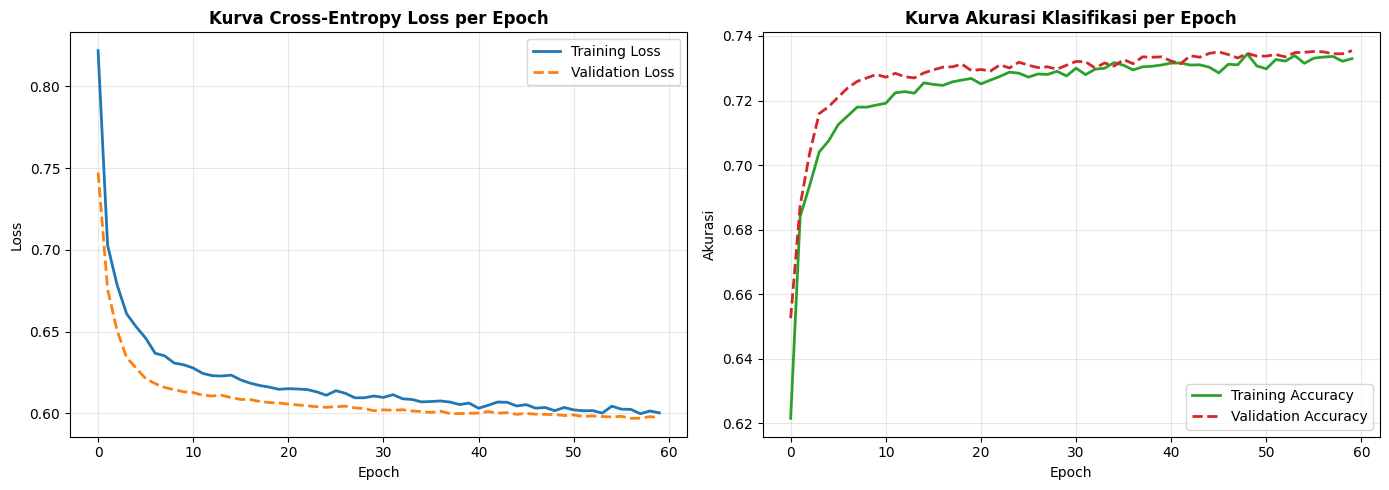


HASIL EVALUASI PADA TEST SET STERIL (8.426 SAMPEL):
  - Test Loss     : 0.5818
  - Test Accuracy : 74.23%

LAPORAN KLASIFIKASI RINCI (TEST SET):
              precision    recall  f1-score   support

       Murah     0.7761    0.8081    0.7918      2809
      Sedang     0.6506    0.5821    0.6144      2809
       Mahal     0.7865    0.8369    0.8109      2808

    accuracy                         0.7423      8426
   macro avg     0.7377    0.7424    0.7390      8426
weighted avg     0.7377    0.7423    0.7390      8426



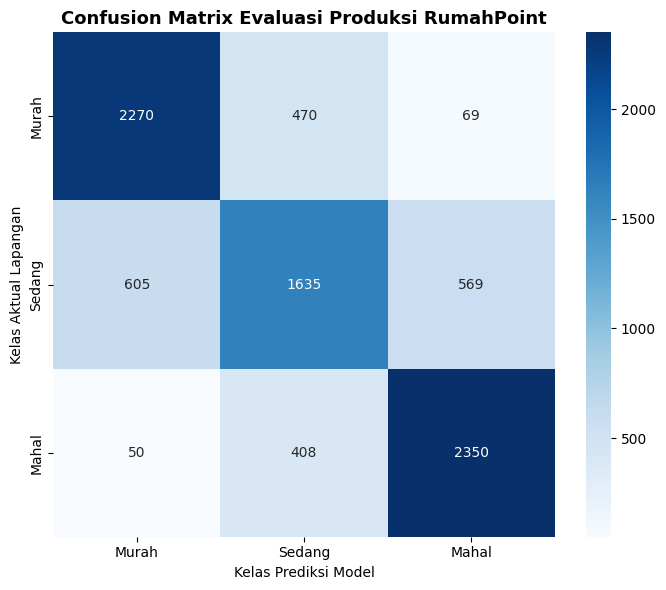

[METRIK] Macro-Averaged ROC-AUC (One-vs-Rest): 0.8957


In [9]:
# ==============================================================================
# 9. EVALUASI TEST SET STERIL: KURVA, LAPORAN KLASIFIKASI, HEATMAP, & ROC-AUC
# ==============================================================================
# 1. Visualisasi Kurva Konvergensi Pelatihan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(history.history['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0].set_title('Kurva Cross-Entropy Loss per Epoch', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot Akurasi
axes[1].plot(history.history['accuracy'], label='Training Accuracy', color='#2ca02c', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#d62728', linewidth=2, linestyle='--')
axes[1].set_title('Kurva Akurasi Klasifikasi per Epoch', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Evaluasi pada Test Set Steril
test_loss, test_acc = model.evaluate(X_test_proc, y_test, verbose=0)
print(f"\n{'='*55}")
print(f"HASIL EVALUASI PADA TEST SET STERIL (8.426 SAMPEL):")
print(f"  - Test Loss     : {test_loss:.4f}")
print(f"  - Test Accuracy : {test_acc * 100:.2f}%")
print(f"{'='*55}\n")

# 3. Prediksi Probabilitas & Kelas
y_pred_proba = model.predict(X_test_proc, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

# 4. Laporan Klasifikasi Rinci
print("LAPORAN KLASIFIKASI RINCI (TEST SET):")
print(classification_report(y_test, y_pred, target_names=label_classes, digits=4))

# 5. Visualisasi Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_classes, yticklabels=label_classes)
plt.title('Confusion Matrix Evaluasi Produksi RumahPoint', fontsize=13, fontweight='bold')
plt.xlabel('Kelas Prediksi Model')
plt.ylabel('Kelas Aktual Lapangan')
plt.tight_layout()
plt.show()

# 6. Perhitungan Macro ROC-AUC (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
macro_roc_auc = roc_auc_score(y_test_bin, y_pred_proba, multi_class='ovr', average='macro')
print(f"[METRIK] Macro-Averaged ROC-AUC (One-vs-Rest): {macro_roc_auc:.4f}")


---

# Bagian 3 — Serialisasi Artefak & Verifikasi Inferensi Input Mentah

Pada bagian ini, kita mengekspor seluruh artefak yang diperlukan untuk deployment ke folder `artifacts/`:

### Mengapa Format Native `.keras` Direkomendasikan Dibanding `.h5` Legacy?
1. **Standar Resmi Keras 3 Modern:** Format file `.keras` merupakan format arsip zip terstandarisasi yang diperkenalkan Keras 3 untuk menggantikan format HDF5 (`.h5`) warisan masa lalu.
2. **Keamanan & Integritas File:** Format `.keras` menyimpan arsitektur graf model dalam format JSON terstruktur, bobot dalam format NumPy array biner, dan konfigurasi optimizer secara aman tanpa mengeksekusi *unsafe code execution* / *pickle bytecode deserialization*.
3. **Portabilitas Antar Framework:** Format `.keras` dirancang multi-backend (TensorFlow, PyTorch, JAX), memastikan fleksibilitas masa depan infrastruktur RumahPoint.

Selain model, kita mengekspor:
- `preprocessor.joblib`: Objek Scikit-Learn `ColumnTransformer` yang telah di-fit.
- `metadata.json`: Kamus konfigurasi operasional penunjang inferensi web server.


In [10]:
# ==============================================================================
# 10. SERIALISASI ARTEFAK PRODUKSI KE FOLDER ARTIFACTS/
# ==============================================================================
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# 1. Simpan Model Deep Learning dalam format native Keras 3 (.keras)
model_path = os.path.join(ARTIFACTS_DIR, "model_rumahpoint.keras")
model.save(model_path)
print(f"[ARTEFAK 1] Model berhasil diekspor: {model_path} ({os.path.getsize(model_path):,} bytes)")

# 2. Simpan Preprocessor Scikit-Learn (ColumnTransformer)
preprocessor_path = os.path.join(ARTIFACTS_DIR, "preprocessor.joblib")
joblib.dump(preprocessor, preprocessor_path)
print(f"[ARTEFAK 2] Preprocessor berhasil diekspor: {preprocessor_path} ({os.path.getsize(preprocessor_path):,} bytes)")

# 3. Susun Metadata Operasional & Catatan Dependency Pinning
metadata_content = {
    'project_name': 'RumahPoint - Price Tier Prediction Service',
    'model_type': 'Deep Neural Network (Feedforward MLP)',
    'model_format': 'Keras 3 Native (.keras)',
    'target_column': 'kelas_harga',
    'label_classes': label_classes,
    'target_mapping': target_mapping,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'top15_locations': top15_locations,
    'price_thresholds': {
        'Murah': '< Rp 483,82 Juta (Kuantil 33,3%)',
        'Sedang': 'Rp 483,82 Juta - Rp 1,235 Miliar (Kuantil 33,3%-66,7%)',
        'Mahal': '> Rp 1,235 Miliar (Kuantil 66,7%)',
        'q1_rupiah': 483819314.0,
        'q2_rupiah': 1235000000.0
    },
    'performance_test': {
        'accuracy': float(test_acc),
        'macro_roc_auc': float(macro_roc_auc)
    },
    'versions': {
        'python': sys.version.split()[0],
        'numpy': np.__version__,
        'pandas': pd.__version__,
        'scikit-learn': sklearn.__version__,
        'tensorflow': tf.__version__,
        'keras': keras.__version__,
        'joblib': joblib.__version__,
        'flask': flask.__version__
    }
}

metadata_path = os.path.join(ARTIFACTS_DIR, "metadata.json")
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_content, f, indent=2)
print(f"[ARTEFAK 3] Metadata operasional berhasil diekspor: {metadata_path} ({os.path.getsize(metadata_path):,} bytes)")


[ARTEFAK 1] Model berhasil diekspor: artifacts/model_rumahpoint.keras (94,032 bytes)
[ARTEFAK 2] Preprocessor berhasil diekspor: artifacts/preprocessor.joblib (4,138 bytes)
[ARTEFAK 3] Metadata operasional berhasil diekspor: artifacts/metadata.json (1,420 bytes)


/tmp/ipykernel_440/2692513601.py:47: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  'flask': flask.__version__


### Verifikasi Inferensi Input Mentah dari Disk

Untuk memastikan artefak yang diekspor dapat bekerja secara mandiri pada server tanpa dependensi ke variabel memori pelatihan, kita memuat ulang model, preprocessor, dan metadata dari disk, lalu mendefinisikan fungsi inferensi mandiri:
`predict_properti(payload, model, preprocessor, metadata)`

Kita menguji 3 skenario properti nyata dari dunia riil:
1. **Skenario 1 (Rumah Kecil Pinggiran):** Luas tanah 60 m², luas bangunan 36 m², 2 kamar tidur, 1 kamar mandi, lokasi `Kab. Sleman`, kondisi `Baru`. Ekspektasi: Kelas **Murah**.
2. **Skenario 2 (Rumah Menengah Kota Besar):** Luas tanah 120 m², luas bangunan 90 m², 3 kamar tidur, 2 kamar mandi, lokasi `Kota Jakarta Selatan`, kondisi `Bekas`. Ekspektasi: Kelas **Sedang / Mahal**.
3. **Skenario 3 (Properti Komersial Tanpa Kamar Luas Besar):** Luas tanah 450 m², luas bangunan 300 m², 0 kamar tidur (`jumlah_kamar=0`), 2 kamar mandi, lokasi `Kota Surabaya`, kondisi `Bekas`. Ekspektasi: Kelas **Mahal**.


In [11]:
# ==============================================================================
# 11. VERIFIKASI INFERENSI MANDIRI PADA 3 SKENARIO PROPERTI MENTAH
# ==============================================================================
# 1. Pemuatan Ulang Seluruh Artefak dari Disk
loaded_model = keras.models.load_model(os.path.join("artifacts", "model_rumahpoint.keras"))
loaded_preprocessor = joblib.load(os.path.join("artifacts", "preprocessor.joblib"))
with open(os.path.join("artifacts", "metadata.json"), 'r', encoding='utf-8') as f:
    loaded_metadata = json.load(f)

print("[INFO] Seluruh artefak berhasil dimuat ulang dari folder artifacts/.")

# 2. Definisi Fungsi Inferensi Input Mentah
def predict_properti(payload, model_obj, preprocessor_obj, meta_obj):
    """
    Menerima payload dictionary mentah, melakukan preprocessing anti-leakage,
    dan mengembalikan hasil inferensi probabilitas beserta kelas harga.
    """
    raw_loc = str(payload.get('lokasi_bersih', 'Lainnya')).strip()
    top15 = meta_obj.get('top15_locations', [])
    loc_mapped = raw_loc if raw_loc in top15 else 'Lainnya'

    # Konstruksi DataFrame 1 baris
    df_single = pd.DataFrame([{
        'luas_m2': float(payload['luas_m2']),
        'luas_bangunan': float(payload['luas_bangunan']) if payload.get('luas_bangunan') is not None else np.nan,
        'jumlah_kamar': float(payload['jumlah_kamar']),
        'jumlah_kamar_mandi': float(payload['jumlah_kamar_mandi']),
        'lokasi_bersih': loc_mapped,
        'kondisi': str(payload.get('kondisi', 'Tidak diketahui')).strip()
    }])

    # Transformasi fitur via ColumnTransformer
    X_single_proc = preprocessor_obj.transform(df_single).astype(np.float32)

    # Forward Pass Prediksi Probabilitas
    probs = model_obj.predict(X_single_proc, verbose=0)[0]
    class_idx = int(np.argmax(probs))
    classes = meta_obj['label_classes']
    predicted_label = classes[class_idx]

    return {
        'kelas_prediksi': predicted_label,
        'kategori_indeks': class_idx,
        'confidence_persen': round(float(probs[class_idx]) * 100, 2),
        'probabilitas': {cls_name: round(float(p), 4) for cls_name, p in zip(classes, probs)},
        'lokasi_input': raw_loc,
        'lokasi_mapped': loc_mapped
    }

# 3. Uji Coba 3 Skenario Properti Riil
skenario_uji = [
    {
        'nama': 'Skenario 1: Rumah Kecil Pinggiran (Subsidi/Entry-Level)',
        'payload': {
            'luas_m2': 60,
            'luas_bangunan': 36,
            'jumlah_kamar': 2,
            'jumlah_kamar_mandi': 1,
            'lokasi_bersih': 'Kab. Sleman',
            'kondisi': 'Baru'
        }
    },
    {
        'nama': 'Skenario 2: Rumah Menengah Kota Besar (Urban Cluster)',
        'payload': {
            'luas_m2': 120,
            'luas_bangunan': 90,
            'jumlah_kamar': 3,
            'jumlah_kamar_mandi': 2,
            'lokasi_bersih': 'Kota Jakarta Selatan',
            'kondisi': 'Bekas'
        }
    },
    {
        'nama': 'Skenario 3: Properti Komersil Luas Besar (Ruko/Kantor Kamar=0)',
        'payload': {
            'luas_m2': 450,
            'luas_bangunan': 300,
            'jumlah_kamar': 0,
            'jumlah_kamar_mandi': 2,
            'lokasi_bersih': 'Kota Surabaya',
            'kondisi': 'Bekas'
        }
    }
]

print("\n" + "=" * 70)
print("HASIL VERIFIKASI INFERENSI 3 SKENARIO PROPERTI REAL WORLD:")
print("=" * 70)
for skenario in skenario_uji:
    hasil = predict_properti(skenario['payload'], loaded_model, loaded_preprocessor, loaded_metadata)
    print(f"\n[{skenario['nama']}]")
    print(f"  - Parameter Input  : {skenario['payload']}")
    print(f"  - Pemetaan Lokasi  : '{hasil['lokasi_input']}' -> '{hasil['lokasi_mapped']}'")
    print(f"  - Kelas Prediksi   : {hasil['kelas_prediksi']} (Keyakinan: {hasil['confidence_persen']}%)")
    print(f"  - Distribusi Prob  : {hasil['probabilitas']}")


[INFO] Seluruh artefak berhasil dimuat ulang dari folder artifacts/.

HASIL VERIFIKASI INFERENSI 3 SKENARIO PROPERTI REAL WORLD:

[Skenario 1: Rumah Kecil Pinggiran (Subsidi/Entry-Level)]
  - Parameter Input  : {'luas_m2': 60, 'luas_bangunan': 36, 'jumlah_kamar': 2, 'jumlah_kamar_mandi': 1, 'lokasi_bersih': 'Kab. Sleman', 'kondisi': 'Baru'}
  - Pemetaan Lokasi  : 'Kab. Sleman' -> 'Lainnya'
  - Kelas Prediksi   : Murah (Keyakinan: 87.72%)
  - Distribusi Prob  : {'Murah': 0.8772, 'Sedang': 0.1224, 'Mahal': 0.0004}

[Skenario 2: Rumah Menengah Kota Besar (Urban Cluster)]
  - Parameter Input  : {'luas_m2': 120, 'luas_bangunan': 90, 'jumlah_kamar': 3, 'jumlah_kamar_mandi': 2, 'lokasi_bersih': 'Kota Jakarta Selatan', 'kondisi': 'Bekas'}
  - Pemetaan Lokasi  : 'Kota Jakarta Selatan' -> 'Lainnya'
  - Kelas Prediksi   : Mahal (Keyakinan: 49.89%)
  - Distribusi Prob  : {'Murah': 0.0656, 'Sedang': 0.4355, 'Mahal': 0.4989}

[Skenario 3: Properti Komersil Luas Besar (Ruko/Kantor Kamar=0)]
  - Param